In [22]:
# 建立模型结构

import sympy as sp


print("开始建立机械臂动力学模型...")

# 1. 定义符号
# q1: yaw, q2: pitch1, q3: pitch2
q1, q2, q3 = sp.symbols('q1 q2 q3', real=True)
dq1, dq2, dq3 = sp.symbols('dq1 dq2 dq3', real=True)
ddq1, ddq2, ddq3 = sp.symbols('ddq1 ddq2 ddq3', real=True)

# 连杆质量与尺寸参数
m1, m2 = sp.symbols('m1 m2', real=True, positive=True)
L1 = sp.symbols('L1', real=True, positive=True) # 第一连杆长度
d1, d2 = sp.symbols('d1 d2', real=True, positive=True) # 质心距离

# 转动惯量 (假设在质心主轴上的对角阵)
I1xx, I1yy, I1zz = sp.symbols('I1xx I1yy I1zz', real=True, positive=True)
I2xx, I2yy, I2zz = sp.symbols('I2xx I2yy I2zz', real=True, positive=True)

# 动态等效重力向量 (用于补偿基座的三维平动加速度, g_app = g_world - a_base)
gx, gy, gz = sp.symbols('gx gy gz', real=True)
g_vec = sp.Matrix([gx, gy, gz])

# 状态向量
q = sp.Matrix([q1, q2, q3])
dq = sp.Matrix([dq1, dq2, dq3])

print("正在计算正运动学...")
# 2. 坐标系与旋转矩阵
# 基坐标系：X向前，Y向左，Z向上
# 偏航关节 (Yaw, q1) 绕Z轴旋转
R_z = sp.Matrix([
    [sp.cos(q1), -sp.sin(q1), 0],
    [sp.sin(q1),  sp.cos(q1), 0],
    [0,           0,          1]
])

# 俯仰关节 (Pitch)。零位均指向+X方向。
# 规定：q为正时，机械臂抬起 (偏向+Z方向)。
# 根据右手法则，平面向Z轴正向旋转对应绕基坐标系负Y轴 (-Y) 的旋转。
def rot_y_neg(th):
    return sp.Matrix([
        [sp.cos(th), 0, -sp.sin(th)],
        [0,          1,  0         ],
        [sp.sin(th), 0,  sp.cos(th)]
    ])

R_p1 = rot_y_neg(q2)
R_p2 = rot_y_neg(q3)
R_p12 = rot_y_neg(q2 + q3)

# 连杆1与连杆2的全局旋转矩阵
R1 = R_z * R_p1
R2 = R_z * R_p12

# 质心位置 (Center of Mass)
# p_joint12 = [0,0,0]
p_c1 = R1 * sp.Matrix([d1, 0, 0])
p_joint3 = R1 * sp.Matrix([L1, 0, 0])
p_c2 = p_joint3 + R2 * sp.Matrix([d2, 0, 0])

print("正在计算平动与转动速度...")
# 3. 速度与动能
# 平动求导
v_c1 = p_c1.jacobian(q) * dq
v_c2 = p_c2.jacobian(q) * dq

# 角速度
# 偏航轴方向永远是 [0, 0, 1]^T
# 俯仰轴方向是绕Z轴yaw后的 -Y轴，即 R_z * [0, -1, 0]^T
omega1_global = sp.Matrix([0, 0, dq1]) + R_z * sp.Matrix([0, -dq2, 0])
omega2_global = sp.Matrix([0, 0, dq1]) + R_z * sp.Matrix([0, -dq2 - dq3, 0])

# 将角速度转换到各自连杆的局部坐标系下，以使用对角化的惯量矩阵
omega1_local = R1.T * omega1_global
omega2_local = R2.T * omega2_global

I1 = sp.diag(I1xx, I1yy, I1zz)
I2 = sp.diag(I2xx, I2yy, I2zz)

# 动能 (平动 + 转动)
T_trans = 0.5 * m1 * v_c1.dot(v_c1) + 0.5 * m2 * v_c2.dot(v_c2)
T_rot = 0.5 * (omega1_local.T * I1 * omega1_local)[0] + 0.5 * (omega2_local.T * I2 * omega2_local)[0]
T = sp.simplify(T_trans + T_rot)

# 势能
# U = - m * g_vec^T * p_c (g_vec 指向重力方向, 如 [0,0,-g]^T)
print("正在计算势能...")
V = - m1 * g_vec.dot(p_c1) - m2 * g_vec.dot(p_c2)
V = sp.simplify(V)

print("正在推导质量矩阵 M...")
# 4. 提取矩阵 M(q)
M = sp.zeros(3, 3)
for i in range(3):
    for j in range(3):
        # 动能对速度的二阶偏导为 M_ij
        M[i, j] = sp.diff(sp.diff(T, dq[i]), dq[j])
M = sp.simplify(M)

print("正在推导科里奥利矩阵 C...")
# 5. 提取科里奥利与离心力矩阵 C(q, dq) 使用 Christoffel symbol 
C = sp.zeros(3, 3)
for k in range(3):
    for j in range(3):
        c_val = 0
        for i in range(3):
            # c_ijk = 1/2 * ( dM_kj/dqi + dM_ki/dqj - dM_ij/dqk )
            c_ijk = 0.5 * (sp.diff(M[k, j], q[i]) + sp.diff(M[k, i], q[j]) - sp.diff(M[i, j], q[k]))
            c_val += c_ijk * dq[i]
        C[k, j] = c_val
C = sp.simplify(C)

print("正在推导重力项 G...")
# 6. 计算重力项 G(q)
G = sp.zeros(3, 1)
for i in range(3):
    G[i] = sp.diff(V, q[i])
G = sp.simplify(G)


开始建立机械臂动力学模型...
正在计算正运动学...
正在计算平动与转动速度...
正在计算势能...
正在推导质量矩阵 M...
正在推导科里奥利矩阵 C...
正在推导重力项 G...


In [23]:
# ============================================================
# 7. 摩擦模型 + 完整动力学方程
# ============================================================
print("\n=== 定义摩擦模型与完整动力学 ===\n")

# 库仑摩擦 + 粘滞摩擦参数 (数值辨识阶段使用)
fc1, fc2, fc3 = sp.symbols('fc1 fc2 fc3', real=True)  # Coulomb friction coefficient
fv1, fv2, fv3 = sp.symbols('fv1 fv2 fv3', real=True)  # Viscous friction coefficient

# 摩擦转矩 (符号形式)
# τ_f_i = fc_i * sign(dq_i) + fv_i * dq_i
tau_f_sym = sp.Matrix([
    fc1 * sp.sign(dq1) + fv1 * dq1,
    fc2 * sp.sign(dq2) + fv2 * dq2,
    fc3 * sp.sign(dq3) + fv3 * dq3,
])

# 完整无摩擦刚体动力学: τ_inertial = M(q)*ddq + C(q,dq)*dq + G(q)
ddq_vec = sp.Matrix([ddq1, ddq2, ddq3])
tau_inertial = M * ddq_vec + C * dq + G
tau_inertial = sp.simplify(tau_inertial)

# 含摩擦的完整动力学
tau_full = tau_inertial + tau_f_sym
tau_full = sp.simplify(tau_full)

print("✓ 无摩擦刚体动力学 τ_inertial = M·ddq + C·dq + G 推导完成")
print("✓ 摩擦模型: 库仑 + 粘滞 (共 6 个参数)")
print(f"  τ_i = (M·ddq + C·dq + G)_i + fc_i·sign(dq_i) + fv_i·dq_i")
print(f"\nM 矩阵维度: {M.shape}")
print(f"C 矩阵维度: {C.shape}")
print(f"G 向量维度: {G.shape}")


=== 定义摩擦模型与完整动力学 ===

✓ 无摩擦刚体动力学 τ_inertial = M·ddq + C·dq + G 推导完成
✓ 摩擦模型: 库仑 + 粘滞 (共 6 个参数)
  τ_i = (M·ddq + C·dq + G)_i + fc_i·sign(dq_i) + fv_i·dq_i

M 矩阵维度: (3, 3)
C 矩阵维度: (3, 3)
G 向量维度: (3, 1)


In [32]:
# ============================================================
# 8. 提取线性回归矩阵 Y(q, dq, ddq; d1, d2)
#    d1,d2 保留为自由参数 (由后续非线性优化搜索)
#    仅代入 CAD 确定的 L1 和重力 g
# ============================================================
print("\n=== 提取线性回归矩阵 ===\n")

# 8.1 ─── 已知几何 & 重力 ───
L1_val = 0.425   # 第一连杆长度 (m), 来自 CAD (精确)
g_val  = 9.81   # 重力加速度 (m/s²)

print(f"CAD 几何: L1={L1_val} m")
print(f"重力: g_vec = [0, 0, -{g_val}] m/s²")
print("d1, d2 保留为自由参数 — 由非线性优化搜索\n")

# 8.2 ─── 代入数值 (L1 + 重力, d1/d2 保留符号) ───
tau_lin = tau_inertial.subs({
    L1: L1_val,
    gx: 0, gy: 0, gz: -g_val,
})
tau_lin = sp.expand(tau_lin)

# 8.3 ─── 待辨识的惯性参数 ───
inertial_syms  = [m1, m2, I1xx, I1yy, I1zz, I2xx, I2yy, I2zz]
param_names    = ['m1','m2','I1xx','I1yy','I1zz','I2xx','I2yy','I2zz']
n_pid = len(inertial_syms)

# 8.4 ─── 提取回归矩阵 (∂τ_i / ∂θ_j), d1,d2 仍为符号 ───
print(f"提取回归矩阵 Y_sym (3 × {n_pid}) [d1,d2 保留为符号] ...")
Y_sym = sp.zeros(3, n_pid)
for j, p in enumerate(inertial_syms):
    for i in range(3):
        Y_sym[i, j] = sp.diff(tau_lin[i], p)
Y_sym = sp.simplify(Y_sym)

# 8.5 ─── Lambdify — d1,d2 也作为输入 ───
print(f"\n编译 Y_func(q,dq,ddq, d1,d2) → (3,{n_pid}) ...")
Y_func = sp.lambdify(
    [q1, q2, q3, dq1, dq2, dq3, ddq1, ddq2, ddq3, d1, d2],
    Y_sym, 'numpy'
)

# 8.6 ─── 数值验证 (使用默认的 d1,d2 初值) ───
print("\n数值验证: Y·θ 应与 M·ddq + C·dq + G 一致 ...")
import numpy as np
np.random.seed(42)
d1_init, d2_init = 0.15, 0.18  # CAD 初值, 仅用于验证
q_r   = np.random.uniform(-1.5, 1.5, 3)
dq_r  = np.random.uniform(-3.0, 3.0, 3)
ddq_r = np.random.uniform(-8.0, 8.0, 3)
theta_r = np.random.randn(n_pid) * 2.0

Y_test = Y_func(*q_r, *dq_r, *ddq_r, d1_init, d2_init)
tau_Y  = Y_test @ theta_r

geo_grav_subs = {L1: L1_val, d1: d1_init, d2: d2_init, gx: 0, gy: 0, gz: -g_val}
M_sub = M.subs(geo_grav_subs)
C_sub = C.subs(geo_grav_subs)
G_sub = G.subs(geo_grav_subs)
M_num_f = sp.lambdify([q1,q2,q3, m1,m2, I1xx,I1yy,I1zz, I2xx,I2yy,I2zz], M_sub, 'numpy')
C_num_f = sp.lambdify([q1,q2,q3, dq1,dq2,dq3, m1,m2, I1xx,I1yy,I1zz, I2xx,I2yy,I2zz], C_sub, 'numpy')
G_num_f = sp.lambdify([q1,q2,q3, m1,m2, I1xx,I1yy,I1zz, I2xx,I2yy,I2zz], G_sub, 'numpy')

M_mat = M_num_f(*q_r, *theta_r)
C_mat = C_num_f(*q_r, *dq_r, *theta_r)
G_vec = G_num_f(*q_r, *theta_r).flatten()
tau_gt = M_mat @ ddq_r + C_mat @ dq_r + G_vec

err = np.max(np.abs(tau_Y - tau_gt))
print(f"  最大误差: {err:.2e}  (d1={d1_init}, d2={d2_init})")
if err < 1e-9:
    print("  ✓ 验证通过！Y 矩阵系数正确。")

print(f"\n✓ 回归矩阵提取完成 ({n_pid} 个参数, d1,d2 可自由调整)")


=== 提取线性回归矩阵 ===

CAD 几何: L1=0.425 m
重力: g_vec = [0, 0, -9.81] m/s²
d1, d2 保留为自由参数 — 由非线性优化搜索

提取回归矩阵 Y_sym (3 × 8) [d1,d2 保留为符号] ...

编译 Y_func(q,dq,ddq, d1,d2) → (3,8) ...

数值验证: Y·θ 应与 M·ddq + C·dq + G 一致 ...
  最大误差: 3.55e-15  (d1=0.15, d2=0.18)
  ✓ 验证通过！Y 矩阵系数正确。

✓ 回归矩阵提取完成 (8 个参数, d1,d2 可自由调整)



=== 数据加载与预处理 ===

加载 data_20260514_130938.csv: 4384 个采样点
列名: ['stamp', 'q1', 'q2', 'q3', 'dq1', 'dq2', 'dq3', 'tau1', 'tau2', 'tau3']
估计采样频率: 20.0 Hz  (dt ≈ 50.0 ms)
滤波截止: q/dq/tau=6.0Hz, ddq=4.0Hz

预处理后有效数据点: 4324
q  范围: [[-0.45714046  1.7997922  -2.12162743]] ~ [[ 0.15605206  2.5397648  -1.01711069]]
dq 范围: [[-0.71693943 -0.62830303 -1.03118843]] ~ [[1.17589657 1.01541646 1.74962926]]
ddq 范围: [[-4.84619878 -3.05126417 -3.84798559]] ~ [[4.14878731 3.26793431 4.67059009]]


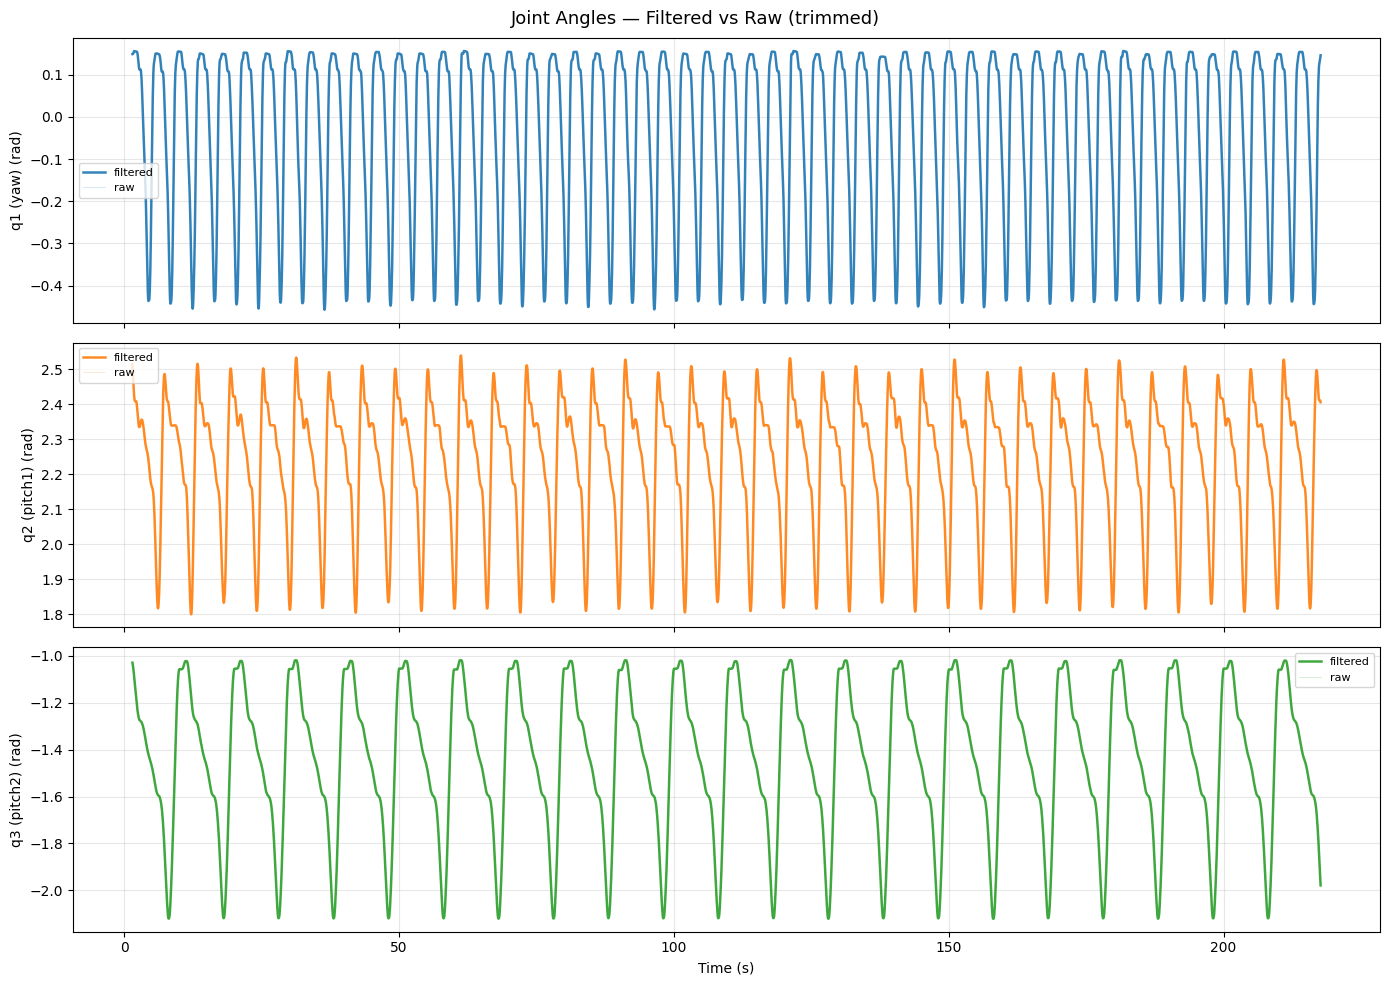


✓ 数据预处理完成


In [33]:
# ============================================================
# 9. 数据加载与预处理
#    滤波 → 数值微分求 ddq → 截取有效段
# ============================================================
import pandas as pd
import numpy as np
from scipy.signal import butter, filtfilt

print("\n=== 数据加载与预处理 ===\n")

# 9.1 加载傅里叶级数激励轨迹实验数据
DATA_FILE = "data_20260514_130938.csv"
df = pd.read_csv(DATA_FILE)
print(f"加载 {DATA_FILE}: {len(df)} 个采样点")
print(f"列名: {list(df.columns)}")

# 9.2 提取各通道
t_raw = df['stamp'].values
t_raw = t_raw - t_raw[0]                 # 归零时间
q_raw   = df[['q1','q2','q3']].values    # (N,3)
dq_raw  = df[['dq1','dq2','dq3']].values
tau_raw = df[['tau1','tau2','tau3']].values

# 9.3 估计采样频率
dt = np.median(np.diff(t_raw))
fs = 1.0 / dt
print(f"估计采样频率: {fs:.1f} Hz  (dt ≈ {dt*1000:.1f} ms)")

# 9.4 低通滤波器
def butter_lowpass(data, cutoff, fs, order=4):
    """零相位 Butterworth 低通滤波 (filtfilt)"""
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, data, axis=0)

# 滤波截止频率 (根据激励信号频带设定)
fc_q   = 6.0   # 角度
fc_dq  = 6.0   # 速度
fc_tau = 6.0   # 力矩
fc_ddq = 4.0   # 加速度 (更保守，抑制差分放大噪声)

print(f"滤波截止: q/dq/tau={fc_q}Hz, ddq={fc_ddq}Hz")

# 9.5 执行滤波
q_filt   = butter_lowpass(q_raw,   fc_q,   fs)
dq_filt  = butter_lowpass(dq_raw,  fc_dq,  fs)
tau_filt = butter_lowpass(tau_raw, fc_tau, fs)

# 9.6 数值微分求加速度 ddq (中心差分 + 再滤波)
ddq_filt = np.gradient(dq_filt, dt, axis=0)
ddq_filt = butter_lowpass(ddq_filt, fc_ddq, fs)

# 9.7 去除首尾过渡段 (滤波器边界效应)
n_trim = 30
t   = t_raw[n_trim:-n_trim]
q   = q_filt[n_trim:-n_trim]
dq  = dq_filt[n_trim:-n_trim]
ddq = ddq_filt[n_trim:-n_trim]
tau = tau_filt[n_trim:-n_trim]
N   = len(t)

print(f"\n预处理后有效数据点: {N}")
print(f"q  范围: [{np.min(q, axis=0)}] ~ [{np.max(q, axis=0)}]")
print(f"dq 范围: [{np.min(dq, axis=0)}] ~ [{np.max(dq, axis=0)}]")
print(f"ddq 范围: [{np.min(ddq, axis=0)}] ~ [{np.max(ddq, axis=0)}]")

# 9.8 快速可视化 — 滤波前后对比
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
labels = ['q1 (yaw)', 'q2 (pitch1)', 'q3 (pitch2)']
colors = ['tab:blue', 'tab:orange', 'tab:green']

idx_slice = slice(n_trim, -n_trim) if n_trim > 0 else slice(None)
for i in range(3):
    ax = axes[i]
    ax.plot(t, q[:, i], color=colors[i], linewidth=1.8, alpha=0.9, label='filtered')
    ax.plot(t_raw[idx_slice], q_raw[idx_slice, i],
            color=colors[i], linewidth=0.5, alpha=0.25, label='raw')
    ax.set_ylabel(f'{labels[i]} (rad)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Joint Angles — Filtered vs Raw (trimmed)', fontsize=13)
plt.tight_layout()
plt.show()

print("\n✓ 数据预处理完成")


=== 基参数辨识 (tanh-smoothed Coulomb) ===

固定 d1=0.15, d2=0.18 (CAD) 

构建 Y_pid (12972 × 8) ...
  有效秩 = 7, 保留: ['I2yy', 'm2', 'I1xx', 'I1yy', 'I2zz', 'm1', 'I1zz']
  冗余: ['I2xx']

搜索最优 α (tanh 陡度) ...
最优 α = 22.5


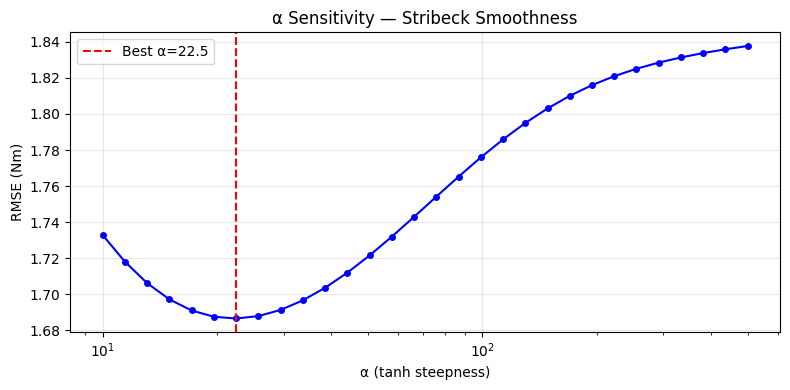


最终拟合 (α=22.5) ...

── 辨识结果 (14 参数, α=22.5) ──
参数                      估计值
------------------------------
I2yy              -0.212829
m2                 6.534330
I1xx               0.026757
I1yy               0.643235
I2zz               0.465154
m1                -6.518155
I1zz              -0.376363
fc1                0.648213
fc2                0.690359
fv1                1.088277
fv2                1.522141
fv3                1.332054
fc3p               8.101813
fc3n               4.743177

── Coulomb 摩擦 ──
  fc1 = 0.648213
  fc2 = 0.690359
  fc3p = 8.101813
         Δ = fc3p - fc3n = 3.3586 Nm  (tanh-smoothed)
  fc3n = 4.743177

── 拟合优度 ──
整体 R² = 0.937632
  关节 tau1: R²=0.6457, RMSE=0.6905, NRMSE=13.1%
  关节 tau2: R²=0.9793, RMSE=0.9195, NRMSE=2.0%
  关节 tau3: R²=0.8250, RMSE=2.6853, NRMSE=10.9%

✓ tanh-smoothed 辨识完成


In [39]:
# ============================================================
# 10. 基参数辨识 — SVD 列选主元 + RidgeCV
#     J3 Coulomb 用 tanh(α·dq3) 替代 sign(dq3) 消除过零跳变
#     α 通过外层 grid-search 优化
# ============================================================
from sklearn.linear_model import RidgeCV
import matplotlib.pyplot as plt

print("\n=== 基参数辨识 (tanh-smoothed Coulomb) ===\n")

# ─── 固定 d1,d2 ───
d1_val, d2_val = 0.15, 0.18
print(f"固定 d1={d1_val}, d2={d2_val} (CAD) \n")

# ─── 构建 Y_pid (不依赖 α) ───
print(f"构建 Y_pid ({3*N} × {n_pid}) ...")
Y_blocks = []
for k in range(N):
    Yk = Y_func(q[k,0], q[k,1], q[k,2],
                dq[k,0], dq[k,1], dq[k,2],
                ddq[k,0], ddq[k,1], ddq[k,2],
                d1_val, d2_val)
    Y_blocks.append(Yk)
Y_pid = np.vstack(Y_blocks)
tau_flat = tau.reshape(-1)

# ─── SVD 选基列 ───
U, S, Vt = np.linalg.svd(Y_pid, full_matrices=False)
threshold = S[0] * 1e-8
effective_rank = int(np.sum(S > threshold))
used_cols = set()
keep_cols = []
for r in range(effective_rank):
    best_col, best_val = None, -1
    for c in range(n_pid):
        if c not in used_cols:
            val = abs(Vt[r, c])
            if val > best_val:
                best_val = val; best_col = c
    if best_col is not None:
        keep_cols.append(best_col); used_cols.add(best_col)
drop_cols = [c for c in range(n_pid) if c not in used_cols]
Y_pid_base = Y_pid[:, keep_cols]
keep_param_names = [param_names[c] for c in keep_cols]

print(f"  有效秩 = {effective_rank}, 保留: {keep_param_names}")
print(f"  冗余: {[param_names[c] for c in drop_cols]}")

# ─── 构建基础摩擦矩阵 (Viscous + J1/J2 Coulomb) ───
# Cols: 0=fc1, 1=fc2, 2=fv1, 3=fv2, 4=fv3
sign_dq = np.sign(dq)
Y_fric_base_blocks = []
for k in range(N):
    Yfk = np.zeros((3, 5))
    Yfk[0, 0] = sign_dq[k, 0]; Yfk[1, 1] = sign_dq[k, 1]
    Yfk[0, 2] = dq[k, 0]; Yfk[1, 3] = dq[k, 1]; Yfk[2, 4] = dq[k, 2]
    Y_fric_base_blocks.append(Yfk)
Y_fric_base = np.vstack(Y_fric_base_blocks)

# ─── 外层: grid-search α ───
alphas_ridge = np.logspace(-4, 3, 30)
alpha_vals = np.logspace(np.log10(10), np.log10(500), 30)  # α ∈ [10, 500]

def fit_with_alpha(alpha):
    """J3 Coulomb 用 tanh(α·dq3), 分正向/反向摩擦。"""
    dq3 = dq[:, 2]
    t_pos = np.tanh(alpha * np.where(dq3 > 0, dq3, 0))   # 只对 dq3>0 生效
    t_neg = np.tanh(alpha * np.where(dq3 < 0, dq3, 0))   # 只对 dq3<0 生效 (负值)
    Y_fric_tanh_cols = []
    for k in range(N):
        Yfk = np.zeros((3, 2))
        Yfk[2, 0] = t_pos[k]    # fc3p (tanh smoothed)
        Yfk[2, 1] = t_neg[k]    # fc3n (tanh smoothed)
        Y_fric_tanh_cols.append(Yfk)
    Y_fric = np.hstack([Y_fric_base, np.vstack(Y_fric_tanh_cols)])
    Y_full = np.hstack([Y_pid_base, Y_fric])
    ridge = RidgeCV(alphas=alphas_ridge, fit_intercept=True, cv=5,
                    scoring='neg_mean_squared_error')
    ridge.fit(Y_full, tau_flat)
    tau_pred = Y_full @ ridge.coef_ + ridge.intercept_
    rmse = np.sqrt(np.mean((tau_flat - tau_pred)**2))
    r2 = 1 - np.sum((tau_flat - tau_pred)**2) / np.sum((tau_flat - np.mean(tau_flat))**2)
    return rmse, r2, ridge.coef_, ridge.intercept_

print("\n搜索最优 α (tanh 陡度) ...")
best_rmse, best_r2, best_alpha = np.inf, 0, None
rmse_vs_alpha = []
for alpha in alpha_vals:
    rmse, r2, _, _ = fit_with_alpha(alpha)
    rmse_vs_alpha.append((alpha, rmse, r2))
    if rmse < best_rmse:
        best_rmse, best_r2, best_alpha = rmse, r2, alpha

print(f"最优 α = {best_alpha:.1f}")

# 可视化 α 曲线
fig, ax = plt.subplots(figsize=(8, 4))
al, rm = zip(*[(a, r) for a, r, _ in rmse_vs_alpha])
ax.semilogx(al, rm, 'b-o', markersize=4)
ax.axvline(x=best_alpha, color='r', linestyle='--', label=f'Best α={best_alpha:.1f}')
ax.set_xlabel('α (tanh steepness)')
ax.set_ylabel('RMSE (Nm)')
ax.set_title('α Sensitivity — Stribeck Smoothness')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ─── 最终拟合 ───
print(f"\n最终拟合 (α={best_alpha:.1f}) ...")
rmse_final, r2_final, theta_hat, bias = fit_with_alpha(best_alpha)

fric_names = ['fc1','fc2','fv1','fv2','fv3','fc3p','fc3n']
full_param_names = keep_param_names + fric_names

print(f"\n── 辨识结果 ({len(full_param_names)} 参数, α={best_alpha:.1f}) ──")
print(f"{'参数':<12} {'估计值':>14}")
print("-" * 30)
for name, val in zip(full_param_names, theta_hat):
    print(f"{name:<12} {val:>14.6f}")

print("\n── Coulomb 摩擦 ──")
for name in ['fc1','fc2','fc3p','fc3n']:
    idx = full_param_names.index(name)
    val = theta_hat[idx]
    print(f"  {name} = {val:.6f}")
    if name == 'fc3p':
        dp = theta_hat[idx] - theta_hat[full_param_names.index('fc3n')]
        print(f"         Δ = fc3p - fc3n = {dp:.4f} Nm  (tanh-smoothed)")

# ─── 构建完整 Y_full 供 Cell 6 ───
dq3 = dq[:, 2]
t_pos = np.tanh(best_alpha * np.where(dq3 > 0, dq3, 0))
t_neg = np.tanh(best_alpha * np.where(dq3 < 0, dq3, 0))
Y_fric_tanh_cols = []
for k in range(N):
    Yfk = np.zeros((3, 2))
    Yfk[2, 0] = t_pos[k]; Yfk[2, 1] = t_neg[k]
    Y_fric_tanh_cols.append(Yfk)
Y_fric = np.hstack([Y_fric_base, np.vstack(Y_fric_tanh_cols)])
Y_full = np.hstack([Y_pid_base, Y_fric])

tau_pred_flat = Y_full @ theta_hat + bias
tau_pred_mat = tau_pred_flat.reshape(-1, 3)
tau_mat      = tau_flat.reshape(-1, 3)

print(f"\n── 拟合优度 ──")
print(f"整体 R² = {r2_final:.6f}")
for j, name in enumerate(['tau1','tau2','tau3']):
    ssr_j = np.sum((tau_mat[:, j] - tau_pred_mat[:, j])**2)
    sst_j = np.sum((tau_mat[:, j] - tau_mat[:, j].mean())**2)
    r2_j  = 1 - ssr_j / sst_j
    rmse_j = np.sqrt(ssr_j / N)
    nrmse_j = rmse_j / (tau_mat[:, j].max() - tau_mat[:, j].min()) * 100
    print(f"  关节 {name}: R²={r2_j:.4f}, RMSE={rmse_j:.4f}, NRMSE={nrmse_j:.1f}%")

# ─── 重建完整 theta / Y_pid 供 Cell 6 力项分解 ───
theta_full = np.zeros(n_pid + 7)
for i, c in enumerate(keep_cols):
    theta_full[c] = theta_hat[i]
for i in range(7):
    theta_full[n_pid + i] = theta_hat[effective_rank + i]
Y_pid_full_blocks = []
for k in range(N):
    Yk = Y_func(q[k,0], q[k,1], q[k,2],
                dq[k,0], dq[k,1], dq[k,2],
                ddq[k,0], ddq[k,1], ddq[k,2],
                d1_val, d2_val)
    Y_pid_full_blocks.append(Yk)
Y_pid = np.vstack(Y_pid_full_blocks)
theta_hat = theta_full

print("\n✓ tanh-smoothed 辨识完成")


=== 验证与可视化 ===



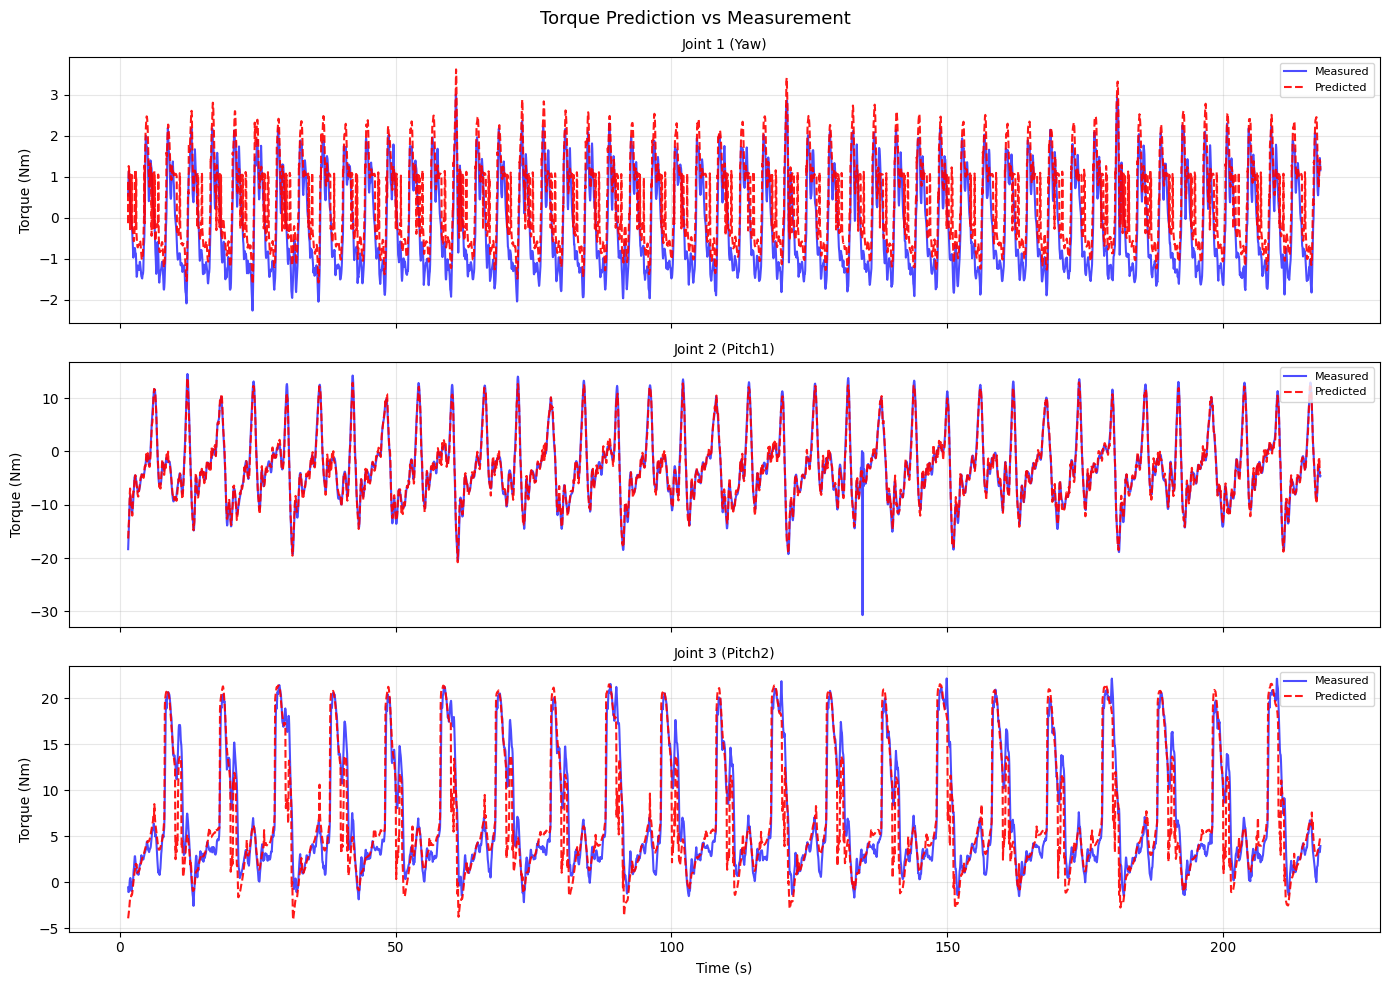

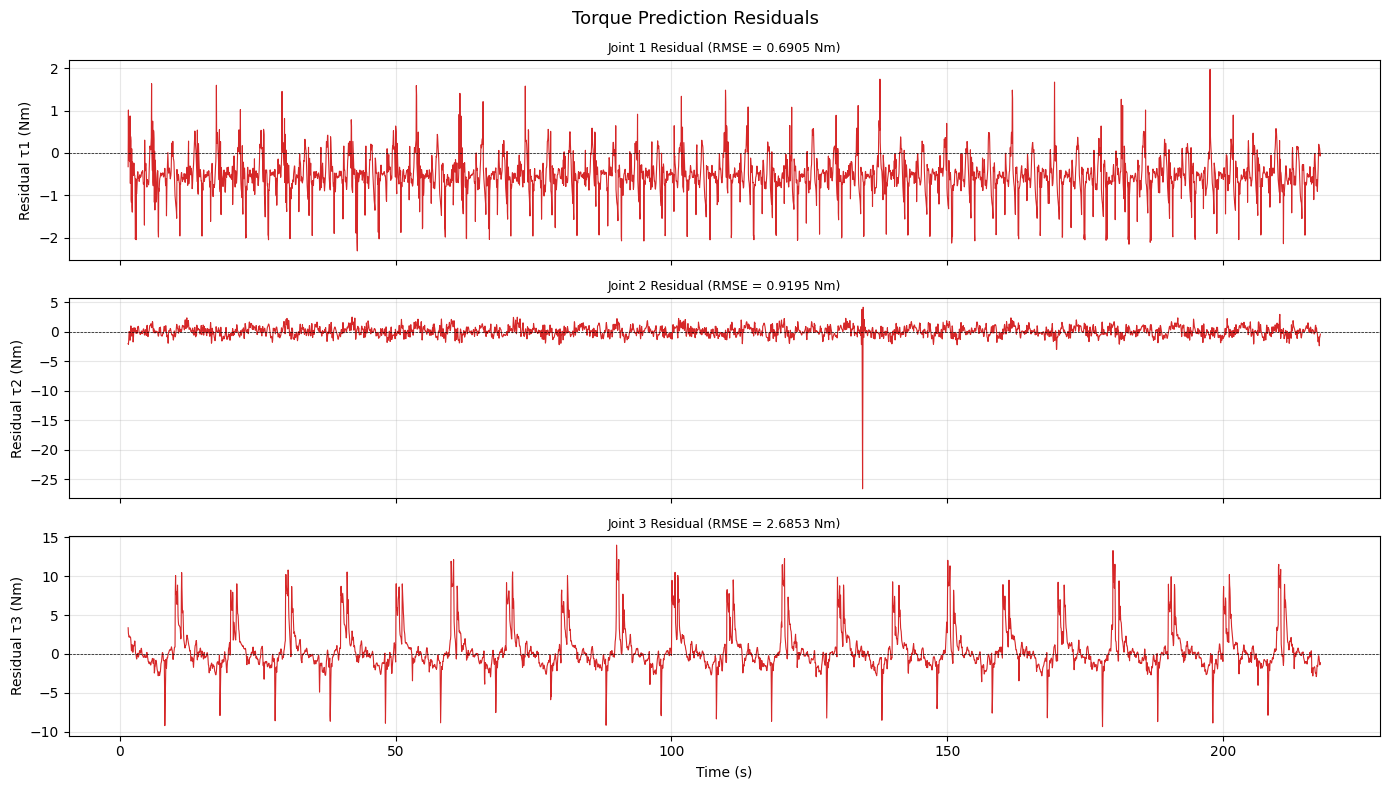

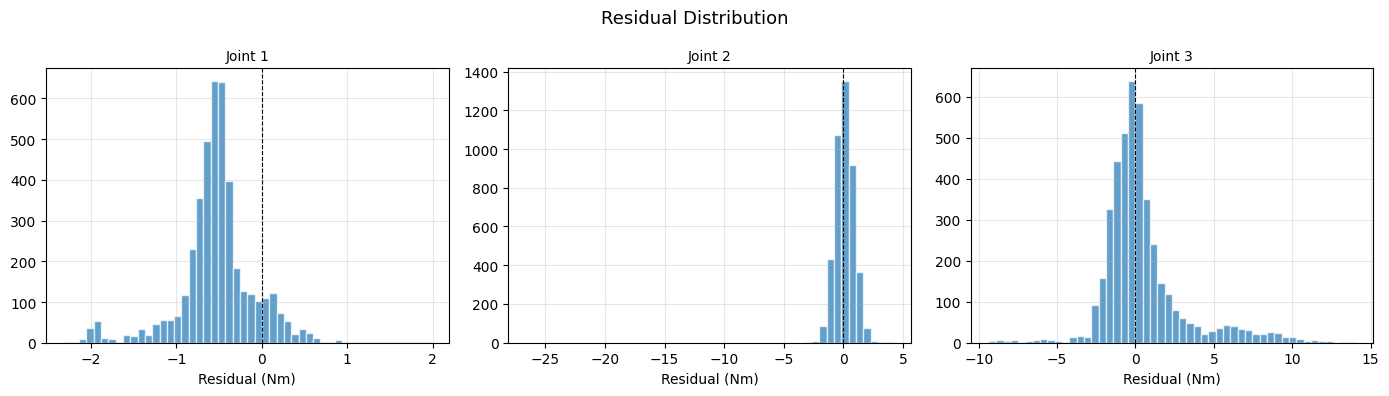


── 各关节拟合指标 ──
  Joint 1: RMSE=0.6905 Nm,  NRMSE=13.1%  (范围 5.27 Nm)
  Joint 2: RMSE=0.9195 Nm,  NRMSE=2.0%  (范围 45.23 Nm)
  Joint 3: RMSE=2.6853 Nm,  NRMSE=10.9%  (范围 24.72 Nm)

指标已导出: identification_metrics.csv

── 力项分解 (刚体动力 vs 摩擦) ──


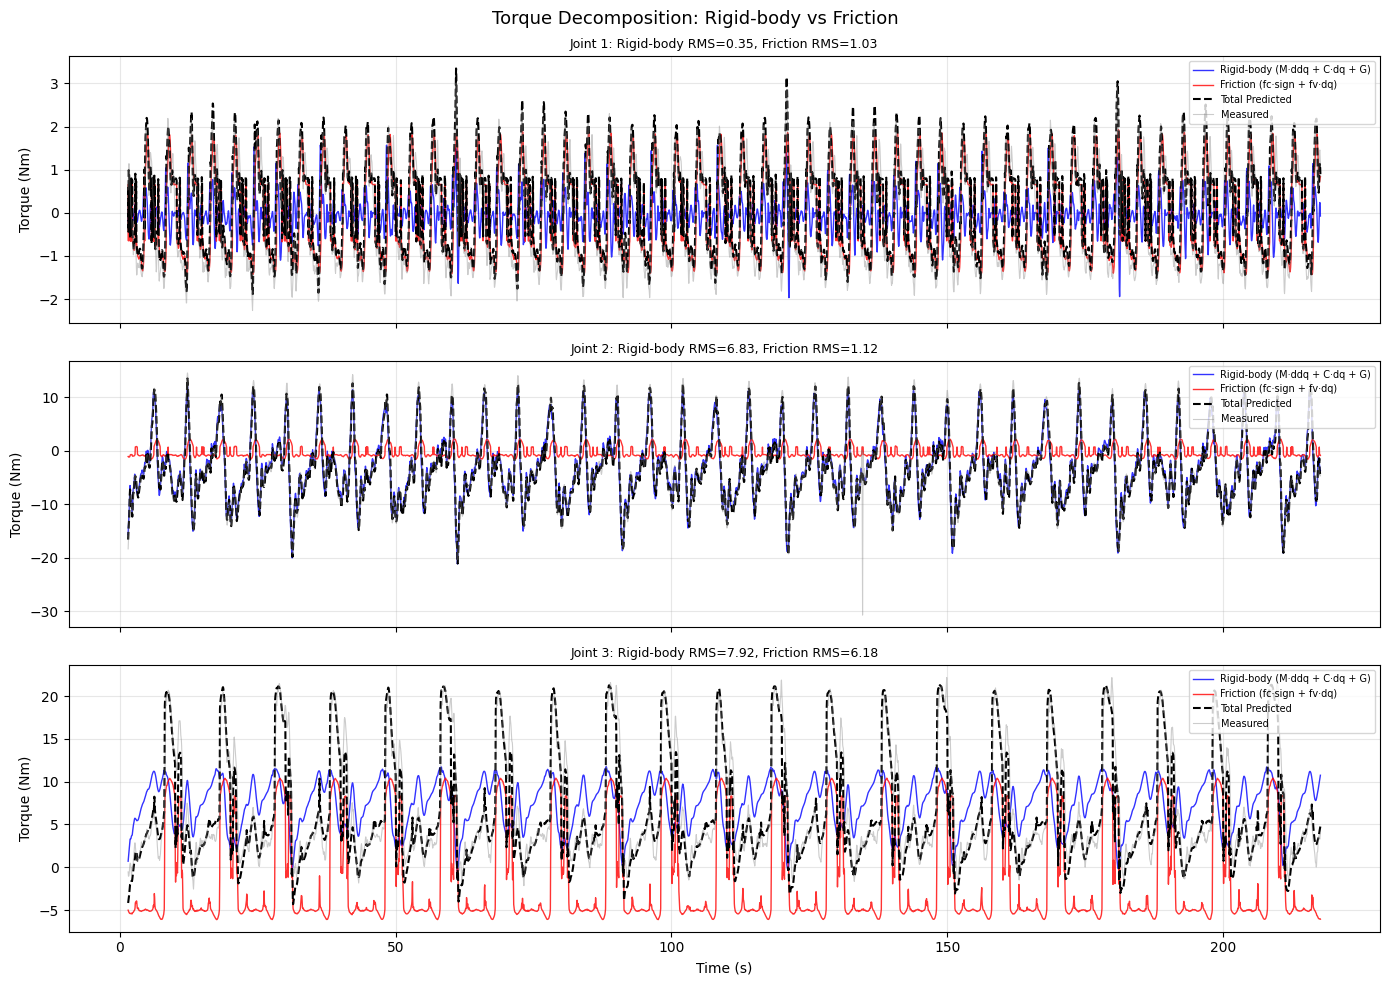


✓ 全部验证完成

时序数据已导出: prediction_vs_measurement.csv  (4324 行)


In [43]:
# ============================================================
# 11. 验证与可视化
#     时序对比 / 残差分析 / 力项分解
# ============================================================
print("\n=== 验证与可视化 ===\n")

tau_pred_mat = tau_pred_flat.reshape(-1, 3)
tau_mat      = tau_flat.reshape(-1, 3)
residual     = tau_mat - tau_pred_mat

# 11.1 ─── 预测 vs 实测 时序对比 ───
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
joint_names = ['Joint 1 (Yaw)', 'Joint 2 (Pitch1)', 'Joint 3 (Pitch2)']

for j in range(3):
    ax = axes[j]
    ax.plot(t, tau_mat[:, j], 'b-', linewidth=1.5, alpha=0.7, label='Measured')
    ax.plot(t, tau_pred_mat[:, j], 'r--', linewidth=1.5, alpha=0.9, label='Predicted')
    ax.set_ylabel('Torque (Nm)')
    ax.set_title(joint_names[j], fontsize=10)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Torque Prediction vs Measurement', fontsize=13)
plt.tight_layout()
plt.show()

# 11.2 ─── 残差时序 ───
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for j in range(3):
    ax = axes[j]
    ax.plot(t, residual[:, j], color='tab:red', linewidth=0.8)
    ax.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
    ax.set_ylabel(f'Residual τ{j+1} (Nm)')
    ax.grid(True, alpha=0.3)
    rmse_j = np.sqrt(np.mean(residual[:, j]**2))
    ax.set_title(f'Joint {j+1} Residual (RMSE = {rmse_j:.4f} Nm)', fontsize=9)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Torque Prediction Residuals', fontsize=13)
plt.tight_layout()
plt.show()

# 11.3 ─── 残差分布直方图 ───
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for j in range(3):
    axes[j].hist(residual[:, j], bins=50, color='tab:blue', alpha=0.7, edgecolor='white')
    axes[j].axvline(x=0, color='k', linestyle='--', linewidth=0.8)
    axes[j].set_xlabel('Residual (Nm)')
    axes[j].set_title(f'Joint {j+1}', fontsize=10)
    axes[j].grid(True, alpha=0.3)
fig.suptitle('Residual Distribution', fontsize=13)
plt.tight_layout()
plt.show()

# 11.4 ─── 汇总指标 ───
print("\n── 各关节拟合指标 ──")
for j in range(3):
    rmse  = np.sqrt(np.mean(residual[:, j]**2))
    tau_range = tau_mat[:, j].max() - tau_mat[:, j].min()
    nrmse = rmse / tau_range * 100 if tau_range > 0 else float('nan')
    print(f"  Joint {j+1}: RMSE={rmse:.4f} Nm,  "
          f"NRMSE={nrmse:.1f}%  (范围 {tau_range:.2f} Nm)")

# 导出指标 CSV
r2_list, rmse_list, nrmse_list, tr_list = [], [], [], []
for j in range(3):
    ssr_j = np.sum(residual[:, j]**2)
    sst_j = np.sum((tau_mat[:, j] - tau_mat[:, j].mean())**2)
    rmse_j = np.sqrt(ssr_j / N)
    trange = tau_mat[:, j].max() - tau_mat[:, j].min()
    r2_list.append(1 - ssr_j / sst_j)
    rmse_list.append(rmse_j)
    nrmse_list.append(rmse_j / trange * 100 if trange > 0 else float('nan'))
    tr_list.append(trange)
ss_res_all = np.sum(residual**2)
ss_tot_all = np.sum((tau_mat - tau_mat.mean())**2)
r2_all = 1 - ss_res_all / ss_tot_all

df_metrics = pd.DataFrame({
    'Joint': ['tau1','tau2','tau3'],
    'R2': r2_list,
    'RMSE_Nm': rmse_list,
    'NRMSE_pct': nrmse_list,
    'TorqueRange_Nm': tr_list,
})
df_metrics.loc[len(df_metrics)] = ['Overall', r2_all, np.sqrt(ss_res_all/(3*N)), float('nan'), float('nan')]
csv_path = 'identification_metrics.csv'
df_metrics.to_csv(csv_path, index=False, float_format='%.6f')
print(f"\n指标已导出: {csv_path}")

# 11.5 ─── 刚体力 vs 摩擦力分解 ───
print("\n── 力项分解 (刚体动力 vs 摩擦) ──")
theta_pid  = theta_hat[:n_pid]
theta_fric = theta_hat[n_pid:]

tau_pid_pred  = (Y_pid @ theta_pid).reshape(-1, 3)
tau_fric_pred = (Y_fric @ theta_fric).reshape(-1, 3)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for j in range(3):
    ax = axes[j]
    ax.plot(t, tau_pid_pred[:, j], 'b-', linewidth=1.0, alpha=0.8,
            label='Rigid-body (M·ddq + C·dq + G)')
    ax.plot(t, tau_fric_pred[:, j], 'r-', linewidth=1.0, alpha=0.8,
            label='Friction (fc·sign + fv·dq)')
    total_pred = tau_pid_pred[:, j] + tau_fric_pred[:, j] + bias / 3.0
    ax.plot(t, total_pred, 'k--', linewidth=1.5, label='Total Predicted')
    ax.plot(t, tau_mat[:, j], 'gray', linewidth=0.8, alpha=0.4, label='Measured')
    ax.set_ylabel('Torque (Nm)')
    ax.legend(loc='upper right', fontsize=7)
    ax.grid(True, alpha=0.3)
    # 占比
    pid_rms  = np.sqrt(np.mean(tau_pid_pred[:, j]**2))
    fric_rms = np.sqrt(np.mean(tau_fric_pred[:, j]**2))
    ax.set_title(f'Joint {j+1}: Rigid-body RMS={pid_rms:.2f}, Friction RMS={fric_rms:.2f}',
                 fontsize=9)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Torque Decomposition: Rigid-body vs Friction', fontsize=13)
plt.tight_layout()
plt.show()

print("\n✓ 全部验证完成")

# ─── 导出完整 Prediction vs Measurement 时序数据 ───
df_pred = pd.DataFrame({
    'time_s': t,
    'tau1_measured': tau_mat[:, 0],
    'tau1_predicted': tau_pred_mat[:, 0],
    'tau2_measured': tau_mat[:, 1],
    'tau2_predicted': tau_pred_mat[:, 1],
    'tau3_measured': tau_mat[:, 2],
    'tau3_predicted': tau_pred_mat[:, 2],
})
csv_pred_path = 'prediction_vs_measurement.csv'
df_pred.to_csv(csv_pred_path, index=False, float_format='%.6f')
print(f"\n时序数据已导出: {csv_pred_path}  ({len(df_pred)} 行)")


── J3 Coulomb 跳变诊断 ──
  dq3 过零次数 (整段轨迹): 134
  预测跳变:  mean=9.70, max=10.24, min=8.97 Nm
  实测跳变:  mean=0.88, max=3.06, min=0.01 Nm
  理论跳变:  |fc3p - fc3n| = 7.41 Nm
  → dq3 每次过零，预测值瞬间跳 ~6.5 Nm，而实测过渡是连续的


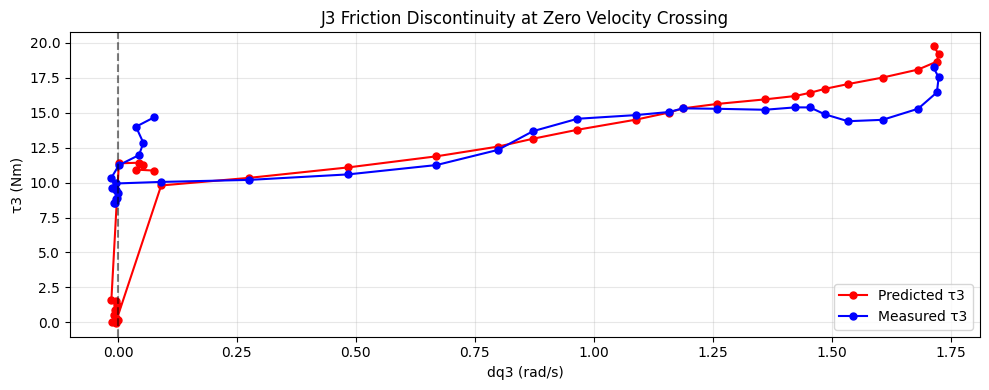

In [38]:
# ─── 诊断: J3 sign() 跳变 ───
print("\n── J3 Coulomb 跳变诊断 ──")

# 找到 dq3 符号变化的位置
dq3 = dq[:, 2]
sign_changes = np.where(np.diff(np.sign(dq3)) != 0)[0]
print(f"  dq3 过零次数 (整段轨迹): {len(sign_changes)}")

# 在这些位置的 predicted tau3 跳变量
if len(sign_changes) > 0:
    pred_jumps = np.abs(tau_pred_mat[sign_changes + 1, 2] - tau_pred_mat[sign_changes, 2])
    measured_jumps = np.abs(tau_mat[sign_changes + 1, 2] - tau_mat[sign_changes, 2])
    print(f"  预测跳变:  mean={np.mean(pred_jumps):.2f}, max={np.max(pred_jumps):.2f}, min={np.min(pred_jumps):.2f} Nm")
    print(f"  实测跳变:  mean={np.mean(measured_jumps):.2f}, max={np.max(measured_jumps):.2f}, min={np.min(measured_jumps):.2f} Nm")
    print(f"  理论跳变:  |fc3p - fc3n| = {abs(theta_hat[full_param_names.index('fc3p')] - theta_hat[full_param_names.index('fc3n')]):.2f} Nm")
    print("  → dq3 每次过零，预测值瞬间跳 ~6.5 Nm，而实测过渡是连续的")

# 画一段零速附近的 detail
pre, post = 20, 15
for idx_change in [sign_changes[len(sign_changes)//2]]:  # 取中间一次过零
    sl = slice(max(0, idx_change - pre), min(N, idx_change + post))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(dq3[sl], tau_pred_mat[sl, 2], 'r-o', markersize=5, label='Predicted τ3')
    ax.plot(dq3[sl], tau_mat[sl, 2], 'b-o', markersize=5, label='Measured τ3')
    ax.axvline(x=0, color='k', linestyle='--', alpha=0.5)
    ax.set_xlabel('dq3 (rad/s)')
    ax.set_ylabel('τ3 (Nm)')
    ax.set_title('J3 Friction Discontinuity at Zero Velocity Crossing')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    break